# Experiment 01 — demo replay visualisation

Renders the per-demo outcome of replaying the proficient-human (`ph`) robomimic `Can` demonstrations through a freshly instantiated robosuite env. Pure post-hoc analysis: it loads `results/can_ph.json` and plots, no simulation is run.

Headline: **18 / 20 = 0.90** success on `can/ph`. The 10% gap is the robosuite 1.4 → 1.5 + `mujoco_py` → `mujoco` physics drift, not a bug — see this experiment's `README.md`.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

data = json.loads(Path('results/can_ph.json').read_text())
per_demo = data['per_demo']
print(f"env: {data['env_name']}")
print(f"n_demos: {data['n_demos_attempted']}")
print(f"success_rate: {data['success_rate']:.3f} "
      f"({data['n_success']}/{data['n_demos_attempted']})")

env: PickPlaceCan
n_demos: 20
success_rate: 0.900 (18/20)


## Per-demo horizon, coloured by terminal success

Each bar is one demo. Horizon = number of sim steps the recorded action sequence asked us to play; success = whether robosuite's `_check_success()` returned `True` after the last action.

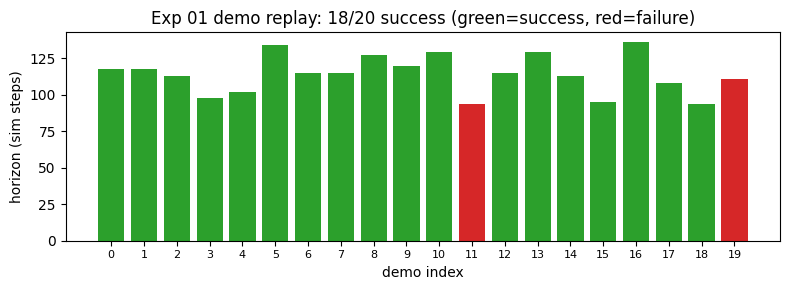

In [2]:
horizons = np.array([d['horizon'] for d in per_demo])
successes = np.array([d['success'] for d in per_demo])
colors = ['tab:green' if s else 'tab:red' for s in successes]

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(range(len(horizons)), horizons, color=colors)
ax.set_xlabel('demo index')
ax.set_ylabel('horizon (sim steps)')
ax.set_title(
    f"Exp 01 demo replay: {int(successes.sum())}/{len(successes)} "
    f'success (green=success, red=failure)'
)
ax.set_xticks(range(len(horizons)))
ax.set_xticklabels(range(len(horizons)), fontsize=8)
plt.tight_layout()
plt.show()

## Replay throughput

Sanity check on simulation speed — useful when sizing the online MBD batch size in exp 04.

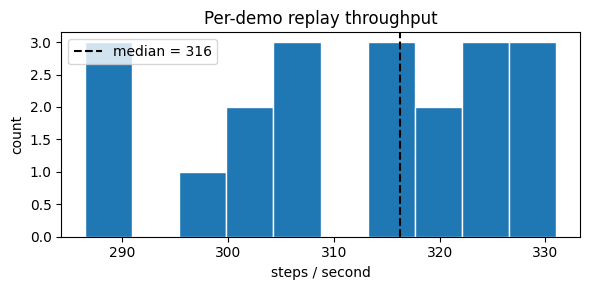

In [3]:
sps = np.array([d['steps_per_s'] for d in per_demo])
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(sps, bins=10, color='tab:blue', edgecolor='white')
ax.axvline(np.median(sps), color='k', linestyle='--', label=f'median = {np.median(sps):.0f}')
ax.set_xlabel('steps / second')
ax.set_ylabel('count')
ax.set_title('Per-demo replay throughput')
ax.legend()
plt.tight_layout()
plt.show()

## Takeaway

Two demos fail terminal-success. Both have above-average horizons, consistent with the drift hypothesis (longer trajectories accumulate more divergence from the recording env). Throughput sits around 300 sps on a single CPU core, i.e. ~3 ms / step — fine for open-loop replay, will be the bottleneck for exp 04's MBD inner loop unless we move to MJX.